# Quanvolutional Neural Networks — a quantum filter in front of a Keras classifier

This code-only notebook follows the PennyLane demo *Quanvolutional Neural Networks* (A. Mari, after Henderson et al. 2019).
It puts a **tiny 4-qubit circuit** to work as an image filter:

1. **Setup** — PennyLane + TensorFlow/Keras, and the author's (optional) CUDA/cuDNN diagnostic.
2. **Data** — 50 training and 30 test digits from MNIST, scaled to $[0,1]$.
3. **The quantum filter** — a 4-qubit circuit: $RY(\pi x)$ encoding of a $2\times2$ pixel patch, one *random* layer, four $\langle Z\rangle$ read-outs.
4. **Quanvolution** — slide the circuit over every image like a $2\times2$, stride-2 convolution: $28\times28\times1 \to 14\times14\times4$.
5. **Models** — the same one-layer softmax head (Keras `Dense(10)`) on the quantum features and on the raw pixels.
6. **Training & results** — validation accuracy and loss of the two models, epoch by epoch.

The quantum layer has **no trainable parameters** (its random angles are frozen): it is a fixed non-linear feature map,
and the plots ask whether such a map helps a linear classifier.

> Backend: the quantum filter runs on PennyLane's **`default.qubit`** statevector simulator in both editions; the `IQM/` edition
> carries a header explaining how the same circuit could be pointed at IQM hardware through the `pennylane-qiskit` plugin.


## 1. Setup

Imports: PennyLane (the quantum circuit and its own NumPy wrapper), TensorFlow/Keras (the data and the classical head), Matplotlib.
The second cell is the author's GPU diagnostic — informative only: on a CPU-only machine it prints *No GPU detected* and the
notebook runs just the same (a few minutes end to end).


In [1]:
#to be used to avoid problems with the GPU
#import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '-1'     # (author's switch) uncomment to hide the GPU from TensorFlow and run on CPU
#os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Reduces the warnings
import os                                      # files and folders (os.makedirs) and environment variables
import pennylane as qml                        # PennyLane: quantum circuits written as Python functions ("QNodes")
from pennylane import numpy as np              # PennyLane's NumPy wrapper: the NumPy API plus a requires_grad flag on every array
from pennylane.templates import RandomLayers   # a ready-made sub-circuit: layers of random single-qubit rotations + CNOTs
import tensorflow as tf                        # TensorFlow: tensors, random seeds, the engine behind Keras
from tensorflow import keras                   # Keras: datasets (MNIST), layers, models, .fit()
import matplotlib.pyplot as plt                # plotting
from IPython.display import display            # show a figure (e.g. a circuit drawing) from the middle of a cell
print("pennylane", qml.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__)


I0000 00:00:1792742471.921291  759153 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792742472.592528  759153 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792742475.428654  759153 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


pennylane 0.45.1 | tensorflow 2.21.0 | keras 3.15.1


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `import pennylane as qml` | the quantum half: `qml.device` builds a simulator, `@qml.qnode` turns a Python function into a runnable circuit, `qml.RY` / `qml.expval` / `qml.PauliZ` are its gates and measurements |
| `from pennylane import numpy as np` | NumPy with a twist: arrays carry a `requires_grad` flag so PennyLane can differentiate through them; nothing is trained *through* the circuit here, so it behaves like plain NumPy |
| `RandomLayers` | a template (a pre-built sub-circuit): rotations about random axes on random wires, interleaved with random CNOTs; the *angles* are the array you pass in, the *structure* comes from a fixed internal seed |
| `import tensorflow as tf`, `from tensorflow import keras` | the classical half: `keras.datasets.mnist`, `keras.models.Sequential`, `.fit()`; TensorFlow itself is only used for `tf.random.set_seed` and `tf.newaxis` |
| the commented `CUDA_VISIBLE_DEVICES = '-1'` | the author's escape hatch: force CPU execution when a broken GPU driver makes TensorFlow crash; harmless to leave commented on a machine without a GPU |

</details>


In [2]:
# =============================================================================
# TEST CUDA/cuDNN CONFIGURATION
# =============================================================================
# The author's GPU diagnostic. It is wrapped in a function + try/except so that it can only ever PRINT:
# on a machine without a GPU (or with the tensorflow-cpu wheel) it reports "No GPU detected" and the notebook goes on.
# Nothing below is needed by the rest of the notebook: a CPU runs it in a few minutes.

def cuda_diagnostic():
    print("=" * 60)
    print("CUDA/cuDNN DIAGNOSTIC")
    print("=" * 60)

    # 1. TensorFlow version and build info
    print("\n[1] TENSORFLOW INFO")
    print("-" * 40)
    import tensorflow as tf                        # already imported above; repeated so the diagnostic is self-contained
    print(f"TensorFlow version: {tf.__version__}")
    print(f"Built with CUDA: {tf.test.is_built_with_cuda()}")            # False for the tensorflow-cpu wheel
    print(f"Built with GPU support: {tf.test.is_built_with_gpu_support()}")

    # 2. CUDA/cuDNN versions TensorFlow was compiled with
    print("\n[2] TF BUILD CONFIGURATION")
    print("-" * 40)
    try:
        from tensorflow.python.platform import build_info
        print(f"CUDA version (build): {build_info.build_info.get('cuda_version', 'N/A')}")
        print(f"cuDNN version (build): {build_info.build_info.get('cudnn_version', 'N/A')}")
    except:
        print("Build info not available")

    # 3. GPUs detected by TensorFlow
    print("\n[3] GPU DEVICES")
    print("-" * 40)
    gpus = tf.config.list_physical_devices('GPU')   # the GPUs TensorFlow can see right now: [] on a CPU-only machine
    if gpus:
        for gpu in gpus:
            print(f"  {gpu}")
            # GPU details
            try:
                details = tf.config.experimental.get_device_details(gpu)
                print(f"    Name: {details.get('device_name', 'N/A')}")
                print(f"    Compute capability: {details.get('compute_capability', 'N/A')}")
            except:
                pass
    else:
        print("  No GPU detected")

    # 4. cuDNN runtime check
    print("\n[4] cuDNN RUNTIME CHECK")
    print("-" * 40)
    try:
        # This forces cuDNN to load
        from tensorflow.python.framework import test_util
        print(f"cuDNN enabled: {tf.test.is_built_with_cuda()}")
    
        # Actual test: create an operation that uses cuDNN
        if gpus:
            try:
                with tf.device('/GPU:0'):                   # force the next operations onto the first GPU
                    # Operation that requires cuDNN
                    x = tf.random.normal([1, 28, 28, 1])
                    conv = tf.keras.layers.Conv2D(32, 3, padding='same')
                    _ = conv(x)
                print("cuDNN test: PASSED ✓")
            except Exception as e:
                print(f"cuDNN test: FAILED ✗")
                print(f"  Error: {e}")
    except Exception as e:
        print(f"Error: {e}")

    # 5. System CUDA version (nvidia-smi)
    print("\n[5] SYSTEM CUDA (nvidia-smi)")
    print("-" * 40)
    import subprocess
    try:
        result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)   # run the NVIDIA driver tool, capture its text
        # Extract the line with the CUDA Version
        for line in result.stdout.split('\n'):
            if 'CUDA Version' in line:
                print(f"  {line.strip()}")
                break
        # Driver version
        for line in result.stdout.split('\n'):
            if 'Driver Version' in line:
                print(f"  {line.strip()}")
                break
    except (FileNotFoundError, OSError):          # no NVIDIA driver installed: nothing to report
        print("  nvidia-smi not found")

    # 6. cuDNN check on the file system
    print("\n[6] cuDNN LIBRARY FILES")
    print("-" * 40)
    import os
    import glob

    cudnn_paths = [                                 # where apt / conda usually put the cuDNN shared libraries
        '/usr/lib/x86_64-linux-gnu/libcudnn*',
        '/usr/local/cuda/lib64/libcudnn*',
        os.path.expanduser('~/anaconda3/envs/*/lib/libcudnn*'),
        os.path.expanduser('~/miniconda3/envs/*/lib/libcudnn*'),
    ]

    found = False
    for pattern in cudnn_paths:
        files = glob.glob(pattern)
        for f in files:
            if 'libcudnn.so' in f or 'libcudnn_' in f:
                print(f"  {f}")
                found = True

    if not found:
        print("  No cuDNN libraries found in common paths")

    # 7. Relevant environment variables
    print("\n[7] ENVIRONMENT VARIABLES")
    print("-" * 40)
    env_vars = ['CUDA_HOME', 'CUDA_PATH', 'LD_LIBRARY_PATH', 'CUDNN_PATH', 
                'CUDA_VISIBLE_DEVICES', 'TF_FORCE_GPU_ALLOW_GROWTH']
    for var in env_vars:
        val = os.environ.get(var, 'not set')        # read an environment variable, with a default if unset
        if len(str(val)) > 50:
            val = val[:50] + '...'
        print(f"  {var}: {val}")

    # 8. Recommendations
    print("\n" + "=" * 60)
    print("RECOMMENDATIONS")
    print("=" * 60)

    try:
        cuda_build = build_info.build_info.get('cuda_version', '')
        cudnn_build = build_info.build_info.get('cudnn_version', '')
    
        print(f"\nYour TensorFlow {tf.__version__} requires:")
        print(f"  - CUDA: {cuda_build}")
        print(f"  - cuDNN: {cudnn_build}")
    
        print(f"\nTo fix cuDNN mismatch, run:")
        print(f"  conda install cudnn={cudnn_build[:3]}* -c conda-forge")
        print(f"\nOr to use CPU only, add at the start of your script:")
        print(f"  import os")
        print(f"  os.environ['CUDA_VISIBLE_DEVICES'] = '-1'")
    except:
        pass

try:
    cuda_diagnostic()                        # run the diagnostic ...
except Exception as e:                       # ... and whatever goes wrong, only report it
    print(f"\nCUDA/cuDNN diagnostic skipped ({e!r}) — this notebook runs on CPU just as well")


CUDA/cuDNN DIAGNOSTIC

[1] TENSORFLOW INFO
----------------------------------------
TensorFlow version: 2.21.0
Built with CUDA: False
Built with GPU support: False

[2] TF BUILD CONFIGURATION
----------------------------------------
CUDA version (build): N/A
cuDNN version (build): N/A

[3] GPU DEVICES
----------------------------------------
  No GPU detected

[4] cuDNN RUNTIME CHECK
----------------------------------------
cuDNN enabled: False

[5] SYSTEM CUDA (nvidia-smi)
----------------------------------------


  | NVIDIA-SMI 470.256.02   Driver Version: 572.60       CUDA Version: 12.8     |
  | NVIDIA-SMI 470.256.02   Driver Version: 572.60       CUDA Version: 12.8     |

[6] cuDNN LIBRARY FILES
----------------------------------------
  /usr/lib/x86_64-linux-gnu/libcudnn_adv.so.9
  /usr/lib/x86_64-linux-gnu/libcudnn_graph_static_v9.a
  /usr/lib/x86_64-linux-gnu/libcudnn_ops_infer_static_v8.a
  /usr/lib/x86_64-linux-gnu/libcudnn_cnn_infer.so.8.6.0
  /usr/lib/x86_64-linux-gnu/libcudnn_cnn_train.so.8
  /usr/lib/x86_64-linux-gnu/libcudnn_engines_runtime_compiled_static_v9.a
  /usr/lib/x86_64-linux-gnu/libcudnn_cnn.so.9.0.0
  /usr/lib/x86_64-linux-gnu/libcudnn_graph.so
  /usr/lib/x86_64-linux-gnu/libcudnn_cnn_train.so.8.6.0
  /usr/lib/x86_64-linux-gnu/libcudnn_adv_infer_static_v8.a
  /usr/lib/x86_64-linux-gnu/libcudnn_ops_infer_static.a
  /usr/lib/x86_64-linux-gnu/libcudnn.so.9
  /usr/lib/x86_64-linux-gnu/libcudnn_cnn.so
  /usr/lib/x86_64-linux-gnu/libcudnn_ops_infer.so.8
  /usr/lib/x86_64-linux

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `tf.test.is_built_with_cuda()`, `tf.config.list_physical_devices('GPU')` | does this TensorFlow *build* know about CUDA, and does it *see* a GPU right now; the two disagree when the driver / cuDNN versions do not match — the mismatch the author was chasing |
| `from tensorflow.python.platform import build_info` | the CUDA and cuDNN versions the wheel was compiled against: a GPU install must provide exactly these |
| `subprocess.run(['nvidia-smi'], capture_output=True, text=True)` | run a shell command from Python and get its stdout as a string; `nvidia-smi` is the driver's own report (CUDA version, driver version) |
| `glob.glob(pattern)`, `os.environ.get(var, 'not set')` | file-name wildcards and environment variables: the last two checks look for the cuDNN library files and the CUDA paths by hand |
| `def cuda_diagnostic(): …` / `try: … except Exception` | the guard we added: the diagnostic is pure printing, so any failure (no driver, CPU-only wheel) is reported and ignored instead of stopping the notebook |
| the `RECOMMENDATIONS` block | prints the `conda install cudnn=…` line that would fix a version mismatch, or the CPU-only switch of the first cell |

</details>


In [3]:
n_epochs = 30   # Number of optimization epochs   (defined here, but the two .fit() calls below hard-code epochs=50)
n_layers = 1    # Number of random layers         (depth of RandomLayers: 1 layer = 4 random rotations + CNOTs)
n_train = 50    # Size of the train dataset       (MNIST has 60 000: the quantum pre-processing, ~1 s per image, is the bottleneck)
n_test = 30     # Size of the test dataset        (of 10 000)

SAVE_PATH = "./QUANVOLUTION/" # Data saving folder   (relative path: inside the folder Jupyter was started in)
os.makedirs(SAVE_PATH, exist_ok=True)   # create it if missing: np.save() does not create directories
PREPROCESS = True           # If False, skip quantum processing and load data from SAVE_PATH
np.random.seed(0)           # Seed for NumPy random number generator      (fixes the random circuit angles -> reproducible features)
tf.random.set_seed(0)       # Seed for TensorFlow random number generator (fixes the initial weights of the Dense layer and the batch shuffling)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `n_train = 50`, `n_test = 30` | tiny subsets: each image costs 196 circuit simulations, so the whole of MNIST would take hours; the accuracies below are therefore coarse (one test image = 3.3 %) |
| `PREPROCESS = True` | a switch: the expensive quantum step is run once and saved to disk as `.npy`; set it to `False` to reload the saved features and only retrain the heads |
| `os.makedirs(SAVE_PATH, exist_ok=True)` | create the output folder (added: without it `np.save` fails on a fresh machine); `exist_ok` = no error if it is already there |
| `np.random.seed(0)`, `tf.random.set_seed(0)` | two independent random generators, both pinned: NumPy draws the circuit angles (exactly reproducible), TensorFlow the network's initial weights and the shuffling (reproducible up to the last digits: CPU/GPU kernels differ, and after 50 epochs so may a test image or two) |

</details>


## 2. Data: a slice of MNIST

Keras downloads MNIST once (≈ 11 MB, cached in `~/.keras/datasets/`) and returns four NumPy arrays: 60 000 training and
10 000 test images of $28\times28$ grey-level pixels (0–255) with their digit labels (0–9). We keep 50 + 30 of them, scale the
pixels to $[0,1]$ and add a trailing *channel* axis — the layout convolutional code expects, `image[row, column, channel]`.


In [4]:
mnist_dataset = keras.datasets.mnist                                                   # the MNIST loader bundled with Keras
(train_images, train_labels), (test_images, test_labels) = mnist_dataset.load_data()   # nested tuple unpacking: 4 NumPy arrays (downloaded once, then cached)
print("train:", train_images.shape, train_labels.shape, "| test:", test_images.shape, test_labels.shape, "| dtype", train_images.dtype)


train: (60000, 28, 28) (60000,) | test: (10000, 28, 28) (10000,) | dtype uint8


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `keras.datasets.mnist.load_data()` | returns `((x_train, y_train), (x_test, y_test))`; the nested tuple unpacking on the left assigns the four arrays in one line |
| `.shape` → `(60000, 28, 28)` and `(60000,)` | 60 000 images of 28×28 pixels (`uint8`, 0–255) and one integer label per image; the test split has 10 000 of each |

</details>


In [5]:
# Reduce dataset size
train_images = train_images[:n_train]          # slicing along the first axis: keep the first 50 images ...
train_labels = train_labels[:n_train]          # ... and their labels (same positions)
test_images = test_images[:n_test]
test_labels = test_labels[:n_test]

# Normalize pixel values within 0 and 1
train_images = train_images / 255              # element-wise: uint8 0..255 -> float 0..1 (the RY angle below is pi * pixel)
test_images = test_images / 255

# Add extra dimension for convolution channels
train_images = np.array(train_images[..., tf.newaxis], requires_grad=False)   # (50, 28, 28) -> (50, 28, 28, 1): "..." = all existing axes, tf.newaxis (= None) adds one
test_images = np.array(test_images[..., tf.newaxis], requires_grad=False)     # requires_grad=False: plain data, PennyLane must not try to differentiate it
print("train_images", train_images.shape, "| test_images", test_images.shape,
      "| pixel range", float(train_images.min()), "-", float(train_images.max()), "| labels", train_labels[:10])


train_images (50, 28, 28, 1) | test_images (30, 28, 28, 1) | pixel range 0.0 - 1.0 | labels [5 0 4 1 9 2 1 3 1 4]


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `train_images[:n_train]` | NumPy slicing on the first (sample) axis; the labels are sliced with the same bound so image *i* keeps label *i* |
| `train_images / 255` | divides every pixel: the values become the inputs of the encoding rotation $RY(\pi x)$ with $x\in[0,1]$ |
| `train_images[..., tf.newaxis]` | `...` stands for "all the axes there are", `tf.newaxis` (an alias of `None`) appends a length-1 axis: `(50, 28, 28)` → `(50, 28, 28, 1)`, one grey channel — convolutional code indexes `image[row, col, channel]` |
| `np.array(..., requires_grad=False)` | PennyLane's NumPy marks arrays as trainable by default; the data is not, so the flag is switched off (this also keeps the arrays plain when they are fed to the circuit) |

</details>


## 3. The quantum filter: a 4-qubit circuit

The filter takes the **four pixel values** $(x_0,x_1,x_2,x_3)\in[0,1]^4$ of a $2\times2$ patch and returns **four numbers** in $[-1,1]$:

$$|0000\rangle \;\xrightarrow{\;RY(\pi x_0)\otimes RY(\pi x_1)\otimes RY(\pi x_2)\otimes RY(\pi x_3)\;}\;
\xrightarrow{\;\text{RandomLayers}(\theta)\;}\; \big(\langle Z_0\rangle,\langle Z_1\rangle,\langle Z_2\rangle,\langle Z_3\rangle\big).$$

The encoding is *angle encoding* (a pixel of 0 leaves the qubit in $|0\rangle$, a pixel of 1 flips it to $|1\rangle$, grey levels
land in between), the random layer scrambles and entangles, and the $Z$ expectation values are the output "pixels".
The angles $\theta$ are drawn once from `np.random` and **never trained**.


rand_params = [[3.725 5.305 5.391 5.323]]  shape (1, 4)
circuit(phi) = [1.0, -0.2007, 0.6378, 0.2007]


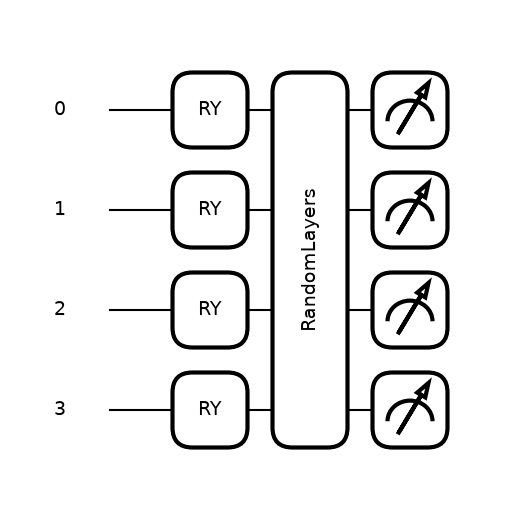

↑ the quantum filter: one RY(π·pixel) per qubit, then the RandomLayers template (its angle matrix M0 = rand_params), then ⟨Z⟩ on every wire


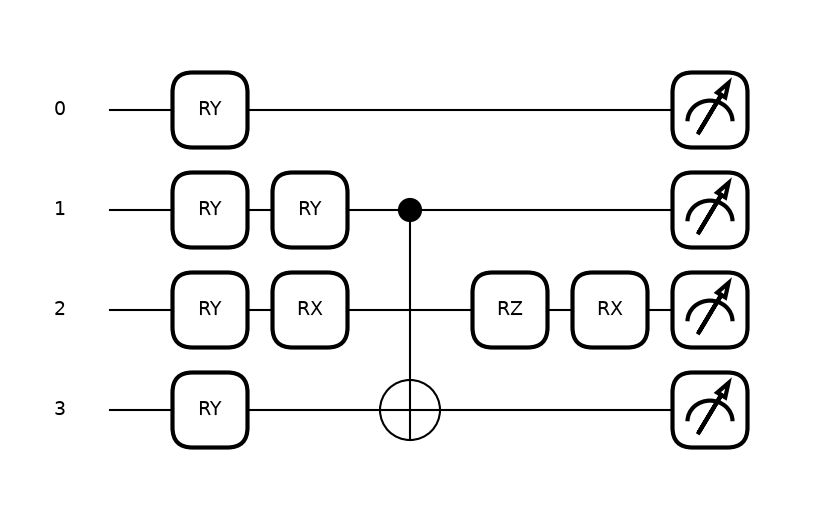

↑ the same circuit with RandomLayers expanded: four random rotations (one per parameter) and the CNOT the template's internal seed placed between wires 1 and 3
0: ──RY(0.00)──────────────────────────────────┤  <Z>
1: ──RY(0.79)──RY(3.72)─╭●─────────────────────┤  <Z>
2: ──RY(1.57)──RX(5.30)─│───RZ(5.39)──RX(5.32)─┤  <Z>
3: ──RY(3.14)───────────╰X─────────────────────┤  <Z>


In [6]:
dev = qml.device("default.qubit", wires=4)                          # the backend: PennyLane's exact statevector simulator of 4 qubits (wires = qubits)
# Random circuit parameters
rand_params = np.random.uniform(high=2 * np.pi, size=(n_layers, 4))  # angles in [0, 2pi) for RandomLayers: shape (layers, parameters per layer) = (1, 4)

@qml.qnode(dev)                                                      # decorator: the function below becomes a QNode = a circuit executed on dev whenever it is called
def circuit(phi):
    # Encoding of 4 classical input values
    for j in range(4):
        qml.RY(np.pi * phi[j], wires=j)                              # rotation about Y by pi*pixel on qubit j: |0> -> cos(pi x/2)|0> + sin(pi x/2)|1>

    # Random quantum circuit
    RandomLayers(rand_params, wires=list(range(4)))                  # the template: random rotations (angles = rand_params) + random CNOTs on the 4 wires

    # Measurement producing 4 classical output values
    return [qml.expval(qml.PauliZ(j)) for j in range(4)]             # <Z_j> for each qubit: 4 numbers in [-1, +1], exact on a statevector simulator

print("rand_params =", np.round(rand_params, 3), " shape", rand_params.shape)
phi = np.array([0.0, 0.25, 0.5, 1.0])                                # an example 2x2 patch (pixel values), flattened row by row
print("circuit(phi) =", [round(float(v), 4) for v in circuit(phi)])  # the 4 expectation values for this patch

fig, ax = qml.draw_mpl(circuit)(phi); display(fig); plt.close(fig)   # draw_mpl(qnode)(args) -> (figure, axes): the circuit as written, the template folded into one box
print("↑ the quantum filter: one RY(π·pixel) per qubit, then the RandomLayers template (its angle matrix M0 = rand_params), then ⟨Z⟩ on every wire")
fig, ax = qml.draw_mpl(circuit, level="device")(phi); display(fig); plt.close(fig)   # level="device": the template expanded into the gates actually simulated
print("↑ the same circuit with RandomLayers expanded: four random rotations (one per parameter) and the CNOT the template's internal seed placed between wires 1 and 3")
print(qml.draw(circuit, level="device")(phi))                        # text version of the drawing (angles in radians)


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `qml.device("default.qubit", wires=4)` | builds the backend: PennyLane's reference statevector simulator; `wires` names the qubits (0–3). Swap this one line for another device (a GPU simulator, a QPU plugin) and the rest is unchanged |
| `@qml.qnode(dev)` | a decorator (`circuit = qml.qnode(dev)(circuit)`): the plain Python function that *describes* gates becomes an executable quantum node bound to `dev`; calling `circuit(phi)` records the gates and runs them |
| `qml.RY(np.pi * phi[j], wires=j)` | angle encoding: $RY(\theta)\|0\rangle = \cos\frac\theta2\|0\rangle + \sin\frac\theta2\|1\rangle$; pixel 0 → $\|0\rangle$, pixel 1 → $\|1\rangle$, grey levels in between |
| `RandomLayers(rand_params, wires=…)` | the template reads `rand_params.shape = (n_layers, 4)`: per layer, 4 rotations with random axis (RX/RY/RZ) and wire, plus CNOTs with probability `ratio_imprim = 0.3`; the structure comes from the template's default `seed=42`, the angles from our `np.random.seed(0)` |
| `qml.expval(qml.PauliZ(j))` | the measurement: the expectation value $\langle Z_j\rangle = P(0) - P(1)$ of qubit *j*, computed exactly from the statevector (no shots); the list of four is the filter's four output channels |
| `qml.draw_mpl(circuit)(phi)` / `qml.draw(circuit)(phi)` | the drawers are *transforms*: they take the QNode and return a function with the same signature that draws instead of running; `level="device"` shows the gates after the template is expanded |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**The four numbers the cell prints, by hand.** For a qubit in $|0\rangle$, $RY(\theta)|0\rangle = \cos\frac\theta2|0\rangle + \sin\frac\theta2|1\rangle$, so
$\langle Z\rangle = \cos^2\frac\theta2 - \sin^2\frac\theta2 = \cos\theta$. With `np.random.seed(0)` the angles are
$\theta = (3.725,\ 5.305,\ 5.391,\ 5.323)$ and the expanded drawing shows where the template put them: $RY(\theta_0)$ on wire 1,
$RX(\theta_1)\,RZ(\theta_2)\,RX(\theta_3)$ on wire 2, one CNOT from wire 1 to wire 3, **nothing on wire 0**. For the test patch
$\phi = (0,\ 0.25,\ 0.5,\ 1)$:

- *wire 0* — only the encoding: $\langle Z_0\rangle = \cos(\pi\cdot 0) = 1$.
- *wire 1* — two $RY$'s compose: $RY(\pi\phi_1)\,RY(\theta_0) = RY(\pi/4 + 3.725)$, so $\langle Z_1\rangle = \cos(4.510) = -0.2007$. Being the *control* of the CNOT does not change its $Z$ statistics.
- *wire 3* — the CNOT target: $Z_3$ after the gate equals $Z_1 Z_3$ before it, and before it the state is a product, so
  $\langle Z_3\rangle = \langle Z_1\rangle\cdot\cos(\pi\phi_3) = (-0.2007)\cdot\cos\pi = +0.2007$.
- *wire 2* — $RY(\pi/2)$ followed by three rotations about different axes: no shortcut, the simulator gives $0.6378$.

So the cell prints `circuit(phi) = [1.0, -0.2007, 0.6378, 0.2007]`. Note what the random layer did to this seed: channels 0, 1, 2 are each
a function of **one** pixel; only channel 3 — through the CNOT — combines two pixels ($x_1$ and $x_3$).

</details>


In [7]:
def quanv(image):
    """Convolves the input image with many applications of the same quantum circuit."""
    out = np.zeros((14, 14, 4))                        # output feature map: 14x14 "pixels" x 4 channels (channel c = <Z_c>)

    # Loop over the coordinates of the top-left pixel of 2X2 squares
    for j in range(0, 28, 2):                          # rows 0, 2, 4, ..., 26: stride 2, so the patches do not overlap
        for k in range(0, 28, 2):                      # columns, same stride
            # Process a squared 2x2 region of the image with a quantum circuit
            q_results = circuit(                       # one circuit evaluation per patch: 14 * 14 = 196 per image
                [
                    image[j, k, 0],                    # top-left pixel  (row j, column k, channel 0) -> qubit 0
                    image[j, k + 1, 0],                # top-right                                     -> qubit 1
                    image[j + 1, k, 0],                # bottom-left                                   -> qubit 2
                    image[j + 1, k + 1, 0]             # bottom-right                                  -> qubit 3
                ]
            )
            # Assign expectation values to different channels of the output pixel (j/2, k/2)
            for c in range(4):
                out[j // 2, k // 2, c] = q_results[c]  # integer division: patch (j, k) -> output pixel (j/2, k/2); channel c = <Z_c>
    return out

q0 = quanv(train_images[0])                            # try it on the first training image
print("input", train_images[0].shape, "-> output", q0.shape, "| circuit evaluations per image:", 14 * 14,
      "| channel 0 == cos(pi * top-left pixel)? max |diff| =", float(np.abs(q0[:, :, 0] - np.cos(np.pi * train_images[0, ::2, ::2, 0])).max()))


input (28, 28, 1) -> output (14, 14, 4) | circuit evaluations per image: 196 | channel 0 == cos(pi * top-left pixel)? max |diff| = 7.771561172376096e-16


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `np.zeros((14, 14, 4))` | the output tensor, allocated first and filled patch by patch: 14×14 positions × 4 channels |
| `range(0, 28, 2)` | start, stop, step: the top-left corners of non-overlapping 2×2 patches — a stride-2 convolution with a 2×2 kernel and no padding |
| `image[j, k + 1, 0]` | NumPy indexing `[row, column, channel]`; the four pixels are read in row-major order and become the four encoding angles |
| `circuit([...])` | the QNode is called like any function, 196 times per image; each call simulates the 4-qubit circuit from scratch — this loop is the whole cost of the method |
| `out[j // 2, k // 2, c] = q_results[c]` | `//` is integer division: input row 6 → output row 3; the four expectation values of one patch land in the four channels of one output pixel |
| the check on channel 0 | with `np.random.seed(0)` the random layer puts no gate on wire 0, so channel 0 is exactly $\cos(\pi x_{\rm top\text{-}left})$: a recoloured, sub-sampled copy of the digit (max \|diff\| ≈ 10⁻¹⁵, i.e. floating-point rounding) |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Output size of the quanvolution.** The same formula as for a classical convolution, $n_{\rm out} = \lfloor (n_{\rm in} + 2p - k)/s \rfloor + 1$,
with image side $n_{\rm in} = 28$, kernel $k = 2$, stride $s = 2$ and no padding ($p = 0$):

$$ n_{\rm out} = \frac{28 - 2}{2} + 1 = 14 \quad\Longrightarrow\quad 14\times14 = 196 \text{ patches, one circuit each.} $$

Every circuit returns four expectation values, one per output channel, so one image becomes a tensor of shape $(14, 14, 4)$:
$14\cdot14\cdot4 = 784$ numbers — **exactly as many as the $28\cdot28 = 784$ input pixels**. The quantum layer does not compress
the image, it re-codes it; the two Keras heads of Section 5 therefore see inputs of the same width. For the whole data:
`q_train_images.shape = (50, 14, 14, 4)` and `q_test_images.shape = (30, 14, 14, 4)` (printed after the pre-processing).

**Channel 0 is readable by eye.** $\langle Z\rangle = \cos(\pi x)$: background $x = 0 \to +1$ (white), ink $x = 1 \to -1$ (black) — the first
output row of the figure in Section 4 is the digit, inverted and sub-sampled. Channel 3 is the product $\cos(\pi x_1 + \theta_0)\cos(\pi x_3)$
of two pixels: something no linear filter can produce.

</details>


## 4. Quantum pre-processing

The filter is applied once to every image and the results are stored: the circuit is never trained, so there is no reason to
re-run it at every epoch. 80 images × 196 circuits ≈ 15 700 simulations — about a minute on a laptop. With `PREPROCESS = False`
the next cell is skipped and the one after it reloads the saved `.npy` files.


In [8]:
if PREPROCESS == True:                                       # run the quantum filter now (False: reuse the features saved on disk)
    q_train_images = []                                      # a Python list, filled image by image ...
    print("Quantum pre-processing of train images:")
    for idx, img in enumerate(train_images):                 # enumerate: index and image together
        print("{}/{}        ".format(idx + 1, n_train), end="\r")   # progress counter: "\r" rewrites the same line
        q_train_images.append(quanv(img))                    # 196 circuit runs -> one (14, 14, 4) array
    q_train_images = np.asarray(q_train_images)              # ... then stacked into one array (50, 14, 14, 4)

    q_test_images = []
    print("\nQuantum pre-processing of test images:")
    for idx, img in enumerate(test_images):
        print("{}/{}        ".format(idx + 1, n_test), end="\r")
        q_test_images.append(quanv(img))
    q_test_images = np.asarray(q_test_images)

    # Save pre-processed images
    np.save(SAVE_PATH + "q_train_images.npy", q_train_images)   # NumPy's binary format: shape + dtype + data, reloaded with np.load
    np.save(SAVE_PATH + "q_test_images.npy", q_test_images)
    print("\nsaved", q_train_images.shape, "and", q_test_images.shape, "to", SAVE_PATH)


Quantum pre-processing of train images:



Quantum pre-processing of test images:



saved (50, 14, 14, 4) and (30, 14, 14, 4) to ./QUANVOLUTION/


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `for idx, img in enumerate(train_images)` | iterate over the first axis of the array (one image at a time) and count; each `img` has shape `(28, 28, 1)` |
| `print(..., end="\r")` | a one-line progress bar: the carriage return moves the cursor back to the start of the line instead of starting a new one |
| `np.asarray(list_of_arrays)` | stacks 50 arrays of shape `(14, 14, 4)` into one of shape `(50, 14, 14, 4)` — the layout Keras expects, samples first |
| `np.save(path, array)` | `.npy` = NumPy's own binary format (shape, dtype and the raw numbers); the expensive step is done once and the features are reusable in later sessions |

</details>


In [9]:
# Load pre-processed images
q_train_images = np.load(SAVE_PATH + "q_train_images.npy")   # read the .npy back into an array (the same values whether just computed or from an earlier session)
q_test_images = np.load(SAVE_PATH + "q_test_images.npy")
print("q_train_images", q_train_images.shape, "| q_test_images", q_test_images.shape,
      "| value range", round(float(q_train_images.min()), 3), "-", round(float(q_train_images.max()), 3))


q_train_images (50, 14, 14, 4) | q_test_images (30, 14, 14, 4) | value range -1.0 - 1.0


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `np.load(path)` | the inverse of `np.save`; this is the cell that matters when `PREPROCESS = False` — the quantum step is skipped and the features come from disk |
| `.shape` → `(50, 14, 14, 4)` / `(30, 14, 14, 4)` | samples × 14 × 14 output pixels × 4 channels: the quanvolved data set |
| value range `-1 … 1` | expectation values of $Z$; the raw pixels live in $[0, 1]$ instead — the two Keras heads see differently scaled inputs |

</details>


In [10]:
print(SAVE_PATH)   # where the features went: a relative path, i.e. inside the folder Jupyter was started in


./QUANVOLUTION/


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `print(SAVE_PATH)` | a sanity check of the output folder; `"./"` is the current working directory of the kernel |
| relative vs absolute path | if you move the notebook, `PREPROCESS = False` will look for the `.npy` files next to the *new* location — use an absolute path to pin them |

</details>


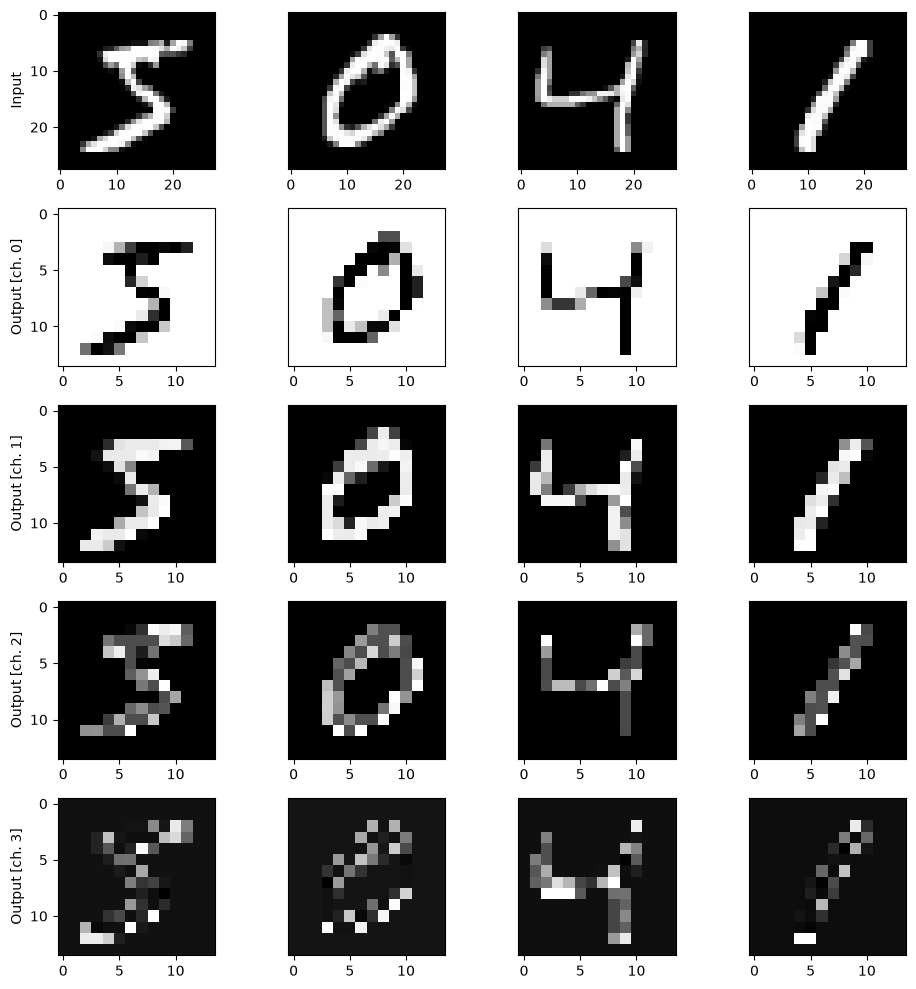

↑ row 0: four input digits (28×28); rows 1–4: the four quanvolution channels (14×14) — channel 0 is the inverted, sub-sampled digit (cos π·pixel), the others recolour or mix neighbouring pixels through the random layer


In [11]:
n_samples = 4                                                   # columns: the first 4 training digits
n_channels = 4                                                  # rows 1-4: the 4 output channels
fig, axes = plt.subplots(1 + n_channels, n_samples, figsize=(10, 10))   # a 5 x 4 grid of axes
for k in range(n_samples):
    axes[0, 0].set_ylabel("Input")
    if k != 0:
        axes[0, k].yaxis.set_visible(False)                     # y axis only on the first column
    axes[0, k].imshow(train_images[k, :, :, 0], cmap="gray")    # row 0: the 28x28 input (channel 0 of sample k) as a grey image

    # Plot all output channels
    for c in range(n_channels):
        axes[c + 1, 0].set_ylabel("Output [ch. {}]".format(c))
        if k != 0:
            axes[c + 1, k].yaxis.set_visible(False)             # (the original indexed axes[c, k] here: an off-by-one, fixed)
        axes[c + 1, k].imshow(q_train_images[k, :, :, c], cmap="gray")   # rows 1-4: the 14x14 map of <Z_c> for sample k

plt.tight_layout()
plt.show()
print("↑ row 0: four input digits (28×28); rows 1–4: the four quanvolution channels (14×14) — channel 0 is the inverted, sub-sampled digit (cos π·pixel), the others recolour or mix neighbouring pixels through the random layer")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plt.subplots(1 + n_channels, n_samples, figsize=(10, 10))` | a 5×4 grid of axes: one row of inputs, one row per output channel, one column per sample |
| `axes[r, c].imshow(array, cmap="gray")` | show a 2-D array as an image, dark = low value; `train_images[k, :, :, 0]` picks sample k, all rows and columns, channel 0 — the trailing axis must be dropped for `imshow` |
| `q_train_images[k, :, :, c]` | channel c of sample k: a 14×14 map of $\langle Z_c\rangle$ values in $[-1, 1]$ |
| `yaxis.set_visible(False)` | keep the y label only on the first column (the original indexed `axes[c, k]` here — an off-by-one we fixed) |

</details>


## 5. The classical head: a one-layer Keras model

The same classifier is used on top of the quantum features and on the raw pixels: flatten the input to a vector, then a single
`Dense(10, softmax)` layer — i.e. **multinomial logistic regression**. Any difference between the two experiments can then only
come from the input representation.


In [12]:
def MyModel():
    """Initializes and returns a custom Keras model
    which is ready to be trained."""
    model = keras.models.Sequential([                   # Sequential: layers applied one after the other
        keras.layers.Flatten(),                         # (14, 14, 4) or (28, 28, 1) -> a vector of 784 numbers (input shape inferred at the first call)
        keras.layers.Dense(10, activation="softmax")    # 10 outputs (one per digit); softmax -> probabilities summing to 1; weights 784x10 + 10 biases
    ])

    model.compile(                                      # compile = choose how to train
        optimizer='adam',                               # Adam: gradient descent with a per-weight adaptive step (default learning rate 0.001)
        loss="sparse_categorical_crossentropy",         # -log p(true class); "sparse" = the labels are integers 0-9, not one-hot vectors
        metrics=["accuracy"],                           # also report the fraction of correct argmax predictions
    )
    return model


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `keras.models.Sequential([...])` | a model as a list of layers; the input shape is not declared, Keras infers it from the first batch it sees — so the same function serves both input shapes |
| `keras.layers.Flatten()` | reshapes each sample to 1-D: 14·14·4 = 784 features for the quantum data, 28·28·1 = 784 for the raw pixels — the same width, by design of the quanvolution |
| `keras.layers.Dense(10, activation="softmax")` | $y = \mathrm{softmax}(Wx + b)$ with $W$ of shape 784×10: a linear classifier; softmax turns the 10 scores into class probabilities |
| `model.compile(optimizer, loss, metrics)` | fixes the training recipe: Adam updates, cross-entropy on integer labels (`sparse_…`), accuracy as the human-readable metric |
| `return model` | each call builds a *fresh* model with new random weights (drawn from the generator seeded by `tf.random.set_seed`), so the two experiments start alike |

</details>


## 6. Training

`model.fit` runs mini-batch gradient descent: 50 images in batches of 4 = 13 steps per epoch, 50 epochs; after every epoch the
model is scored on the 30 test images (`validation_data`). The returned `History` object stores the four curves (loss/accuracy,
train/validation) plotted at the end. First the quantum features, then the raw pixels.


In [13]:
q_model = MyModel()                                  # a fresh model for the quantum features

q_history = q_model.fit(                             # train; returns a History object with the per-epoch metrics
    q_train_images,                                  # inputs: (50, 14, 14, 4)
    train_labels,                                    # targets: (50,) integers 0-9
    validation_data=(q_test_images, test_labels),    # evaluated (not trained on) after every epoch
    batch_size=4,                                    # 4 images per gradient step -> ceil(50/4) = 13 steps per epoch
    #epochs=n_epochs,
    epochs=50,                                       # the author's final choice (n_epochs = 30 above is left unused)
    verbose=2,                                       # one log line per epoch
)
q_model.summary()                                    # layer table + parameter count (available once the input shape is known, i.e. after fit)


Epoch 1/50


13/13 - 1s - 46ms/step - accuracy: 0.1000 - loss: 3.0696 - val_accuracy: 0.1667 - val_loss: 2.3414


Epoch 2/50


13/13 - 0s - 8ms/step - accuracy: 0.3800 - loss: 2.0059 - val_accuracy: 0.1667 - val_loss: 2.2251


Epoch 3/50


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,552 (92.00 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 15,702 (61.34 KB)

<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `model.fit(x, y, validation_data=..., batch_size, epochs, verbose)` | the training loop: shuffle, split into batches, forward pass, loss, back-propagation, Adam update; at the end of every epoch the validation set is scored |
| `batch_size=4` | 13 updates per epoch on 50 images: small batches = noisy gradients, which is partly why the curves below wobble |
| `verbose=2` | the log: `13/13` steps, training `loss` / `accuracy` and `val_loss` / `val_accuracy`; read the `val_` columns — the training accuracy on 50 images is easily driven to 100 % |
| `q_history.history` | a dict of four lists (one value per epoch): `loss`, `accuracy`, `val_loss`, `val_accuracy`, used by the plots in Section 7 |
| `model.summary()` | `Flatten` has no weights; `Dense`: 784×10 + 10 = 7 850 trainable parameters; the *optimizer params* are Adam's two running moments per weight (box below) |

</details>


<details open><summary><b>📐 Working it out</b></summary>

**Parameter count of the Keras head.** `Flatten`: $(14, 14, 4) \to 14\cdot14\cdot4 = 784$ inputs, no parameters.
`Dense(10)`: a weight matrix $W$ of $784\times10 = 7\,840$ entries plus $10$ biases:

$$ 784\cdot 10 + 10 = 7\,850 \text{ trainable parameters.} $$

The classical model flattens $(28, 28, 1)$ to the same $784$ inputs, hence the **same 7 850** — the two heads have identical capacity,
and the quantum layer adds 4 frozen angles (`rand_params`), not trainable parameters.
Adam keeps two running moments (mean and variance of the gradient) for every parameter, plus two scalars (the step counter and
the learning rate): $2\cdot 7\,850 + 2 = 15\,702$ *optimizer params*; the summary's total is $7\,850 + 15\,702 = 23\,552$
(`float32`, 4 bytes each ≈ 92 KB). The summary prints `Total params: 23,552`, `Trainable params: 7,850`, `Optimizer params: 15,702`.

</details>


In [14]:
c_model = MyModel()                                  # the control: the same head on the raw pixels

c_history = c_model.fit(
    train_images,                                    # inputs: (50, 28, 28, 1) pixels in [0, 1]
    train_labels,
    validation_data=(test_images, test_labels),
    batch_size=4,
    #epochs=n_epochs,
    epochs=50,                                       # same recipe as the quantum model
    verbose=2,
)
print("trainable parameters:", c_model.count_params())   # 784 * 10 + 10 = 7 850, exactly as for q_model


Epoch 1/50


13/13 - 1s - 39ms/step - accuracy: 0.0800 - loss: 2.3055 - val_accuracy: 0.2000 - val_loss: 2.2675


Epoch 2/50


13/13 - 0s - 8ms/step - accuracy: 0.4600 - loss: 1.9168 - val_accuracy: 0.3667 - val_loss: 2.1034


Epoch 3/50


...

Epoch 49/50


13/13 - 0s - 7ms/step - accuracy: 1.0000 - loss: 0.0583 - val_accuracy: 0.7000 - val_loss: 1.0217


Epoch 50/50


13/13 - 0s - 7ms/step - accuracy: 1.0000 - loss: 0.0564 - val_accuracy: 0.7000 - val_loss: 1.0203


trainable parameters: 7850


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| same `fit` on `train_images` | the control experiment: identical architecture, seeds and hyper-parameters; only the input representation changes |
| `c_model.count_params()` | 7 850 again (28·28·1 = 784 inputs): the comparison is fair in capacity |
| `val_accuracy` in the log | compare the last epochs with the quantum run above; with 30 test images the two are within one or two images of each other |

</details>


## 7. Results

Validation accuracy and loss of the two models per epoch. With 30 test images one image is worth 3.3 % of accuracy, so read the
curves as a trend, not as a measurement: on this toy scale the quantum features do about as well as the raw pixels. The point of
the exercise is the *pipeline* (quantum feature map → classical learner), not a quantum advantage — Henderson et al. report a
modest edge of the quanvolutional features in larger experiments, with a classical head that is itself convolutional.


In [15]:
print(plt.style.available)   # the names Matplotlib accepts in plt.style.use(...)


['Solarize_Light2', 'bmh', 'classic', 'dark_background', 'fast', 'fivethirtyeight', 'ggplot', 'grayscale', 'petroff10', 'petroff6', 'petroff8', 'seaborn-v0_8', 'seaborn-v0_8-bright', 'seaborn-v0_8-colorblind', 'seaborn-v0_8-dark', 'seaborn-v0_8-dark-palette', 'seaborn-v0_8-darkgrid', 'seaborn-v0_8-deep', 'seaborn-v0_8-muted', 'seaborn-v0_8-notebook', 'seaborn-v0_8-paper', 'seaborn-v0_8-pastel', 'seaborn-v0_8-poster', 'seaborn-v0_8-talk', 'seaborn-v0_8-ticks', 'seaborn-v0_8-white', 'seaborn-v0_8-whitegrid', 'tableau-colorblind10']


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plt.style.available` | the list of built-in style sheets; the next cell uses `"seaborn-v0_8"` (the old `"seaborn"` name was removed in Matplotlib 3.8) |
| `print(list)` | a list prints with brackets and quotes — a quick way to see the exact strings to copy |

</details>


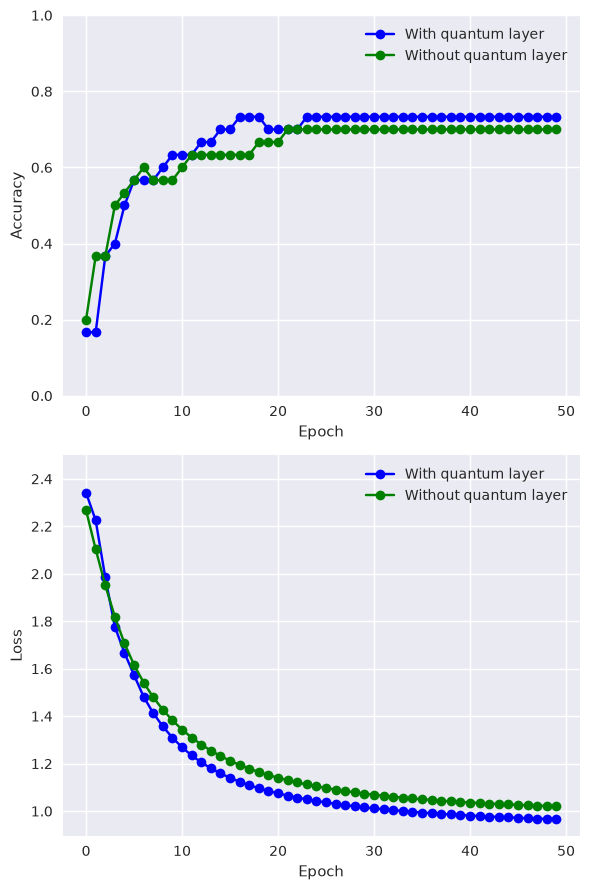

↑ validation accuracy (top) and loss (bottom) per epoch on the 30 test digits: blue = Dense head on the quanvolution features, green = the same head on the raw pixels
final val_accuracy: with quantum layer 0.733 | without 0.700   (1 test image = 0.033)


In [16]:
import matplotlib.pyplot as plt                     # (already imported; harmless to repeat)

plt.style.use("seaborn-v0_8")                       # a global style sheet (grid, colours) for every figure created from now on
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 9))   # two stacked plots; the tuple unpacking names the two axes

ax1.plot(q_history.history["val_accuracy"], "-ob", label="With quantum layer")      # one value per epoch; "-ob" = line, circle markers, blue
ax1.plot(c_history.history["val_accuracy"], "-og", label="Without quantum layer")   # "-og": same, green
ax1.set_ylabel("Accuracy")
ax1.set_ylim([0, 1])                                # fixed axis: a 10-class random guess sits at 0.1
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(q_history.history["val_loss"], "-ob", label="With quantum layer")
ax2.plot(c_history.history["val_loss"], "-og", label="Without quantum layer")
ax2.set_ylabel("Loss")
ax2.set_ylim(top=2.5)                               # cross-entropy of a random guess is ln 10 = 2.30
ax2.set_xlabel("Epoch")
ax2.legend()
plt.tight_layout()
plt.show()
print("↑ validation accuracy (top) and loss (bottom) per epoch on the 30 test digits: blue = Dense head on the quanvolution features, green = the same head on the raw pixels")
print(f"final val_accuracy: with quantum layer {q_history.history['val_accuracy'][-1]:.3f} | without {c_history.history['val_accuracy'][-1]:.3f}"
      f"   (1 test image = {1 / n_test:.3f})")


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `plt.style.use("seaborn-v0_8")` | switches the look of all subsequent figures (background grid, colour cycle); it is global, not per figure |
| `q_history.history["val_accuracy"]` | the list of 50 per-epoch values; plotted against its index, so the x axis is epoch − 1 |
| `"-ob"`, `"-og"` | Matplotlib format strings: `-` line, `o` circle markers, `b` blue / `g` green |
| `ax1.set_ylim([0, 1])`, `ax2.set_ylim(top=2.5)` | fixed axes so that the two runs (and your re-runs) are comparable; chance level is accuracy 0.1 and loss $\ln 10 \approx 2.30$ |
| the final numbers | both heads reach the same ball-park on this toy set; the difference is a few test images and changes with the seeds — see the In-depth analysis for a controlled ablation |

</details>


## 8. 🔬 In-depth analysis

1. **Cost accounting.** Count the circuit evaluations behind this notebook: how many per image, how many for the 80 images used
   here, and how long one image takes on your machine. Extrapolate to the full MNIST (70 000 images) and to a real QPU where every
   evaluation is a job of, say, 1 000 shots at ~1 ms per shot — is "quanvolution of MNIST on hardware" a realistic experiment?
2. **Is the random layer doing anything?** Build a second QNode with the *encoding only* (the four `RY`, no `RandomLayers`).
   Show by hand and numerically that its output channels are $\cos(\pi x_c)$ — a per-pixel recolouring of a sub-sampled image.
   Pre-process the 80 images with it, train the same `MyModel()` head and compare the final validation accuracy with the
   random-layer features and with the raw pixels. Which channels of the random-layer filter genuinely mix pixels (look at the
   expanded drawing in Section 3)?
3. **Capacity.** Verify with `count_params()` and the weight shapes that the two heads have exactly the same number of trainable
   parameters, and that `rand_params` is not among them. How many parameters would a classical `Conv2D(4, kernel_size=2, strides=2)`
   layer — the classical analogue of the quanvolution — add in front of the same head?

Write your code in the empty cell below; a reference solution follows it. Try first, then compare.


In [17]:
# 🔬 In-depth analysis — your code here



In [18]:
# Reference solution
import time                                                               # wall-clock timing

# (1) cost accounting: circuit evaluations per image and their time
per_image = (28 // 2) * (28 // 2)                                         # 14 x 14 patches, one circuit each
t0 = time.perf_counter(); _ = quanv(train_images[0]); dt = time.perf_counter() - t0
print(f"(1) {per_image} circuits per image -> {per_image * (n_train + n_test):,} for the {n_train + n_test} images used here; "
      f"one image takes {dt:.2f} s on this machine")
print(f"    full MNIST (70 000 images): {per_image * 70_000:,} circuits ≈ {per_image * 70_000 * dt / 3600:.1f} h of simulation here; "
      f"on a QPU at 1000 shots x 1 ms = 1 s per circuit ≈ {per_image * 70_000 / 3600:,.0f} h of pure QPU time, before queueing")

# (2) ablation: the same filter without the random layer
@qml.qnode(dev)
def circuit_enc(phi):                                                     # encoding only: four RY, no RandomLayers
    for j in range(4):
        qml.RY(np.pi * phi[j], wires=j)
    return [qml.expval(qml.PauliZ(j)) for j in range(4)]

patch = np.array([0.0, 0.25, 0.5, 1.0])
print(f"(2) encoding only: circuit_enc(patch) = {[round(float(v), 4) for v in circuit_enc(patch)]}  vs  cos(pi*patch) = {[round(float(v), 4) for v in np.cos(np.pi * patch)]}")

def quanv_enc(image):                                                     # the same sliding window with the encoding-only circuit
    out = np.zeros((14, 14, 4))
    for j in range(0, 28, 2):
        for k in range(0, 28, 2):
            q = circuit_enc([image[j, k, 0], image[j, k + 1, 0], image[j + 1, k, 0], image[j + 1, k + 1, 0]])
            for c in range(4):
                out[j // 2, k // 2, c] = q[c]
    return out

e_train = np.asarray([quanv_enc(img) for img in train_images])            # list comprehension over the 50 + 30 images (~1 min)
e_test = np.asarray([quanv_enc(img) for img in test_images])
closed_form = np.stack([np.cos(np.pi * train_images[:, a::2, b::2, 0]) for a in (0, 1) for b in (0, 1)], axis=-1)   # cos(pi*pixel) at the 4 positions of every patch
print(f"    max |circuit - closed form cos(pi x)| over the training set = {float(np.abs(e_train - closed_form).max()):.1e}")

tf.random.set_seed(0)                                                     # restart the TensorFlow generator before building the third head
e_model = MyModel()
e_history = e_model.fit(e_train, train_labels, validation_data=(e_test, test_labels), batch_size=4, epochs=50, verbose=0)   # verbose=0: silent
final = lambda h: h.history["val_accuracy"][-1]                           # the last epoch's validation accuracy
print(f"    final val_accuracy: random layer {final(q_history):.3f} | encoding only {final(e_history):.3f} | raw pixels {final(c_history):.3f}   (1 test image = {1 / n_test:.3f})")
print("    with seed 0 only channel 3 of the random-layer filter mixes pixels (<Z1><Z3> through the CNOT); channels 0, 1, 2 are functions of a single pixel")

# (3) capacity: the trainable parameters of the heads, and the classical analogue of the quantum filter
print(f"(3) trainable parameters: quantum head {q_model.count_params():,} | classical head {c_model.count_params():,} | encoding-only head {e_model.count_params():,}")
print("    weight shapes:", [tuple(w.shape) for w in q_model.trainable_weights], "= 784*10 + 10;  rand_params", tuple(rand_params.shape), "= 4 frozen angles outside Keras")
conv = keras.layers.Conv2D(4, kernel_size=2, strides=2)                   # the classical analogue: 4 filters of 2x2 on 1 input channel, stride 2
conv.build((None, 28, 28, 1))                                             # create its weights for a 28x28x1 input (None = any batch size)
print(f"    a classical Conv2D(4, 2x2, stride 2) in front of the head would add {conv.count_params()} trainable parameters (2*2*1*4 weights + 4 biases)"
      f" and output {tuple(conv.compute_output_shape((None, 28, 28, 1))[1:])} — the same shape as the quanvolution")


(1) 196 circuits per image -> 15,680 for the 80 images used here; one image takes 0.59 s on this machine
    full MNIST (70 000 images): 13,720,000 circuits ≈ 2239.7 h of simulation here; on a QPU at 1000 shots x 1 ms = 1 s per circuit ≈ 3,811 h of pure QPU time, before queueing
(2) encoding only: circuit_enc(patch) = [1.0, 0.7071, 0.0, -1.0]  vs  cos(pi*patch) = [1.0, 0.7071, 0.0, -1.0]


    max |circuit - closed form cos(pi x)| over the training set = 7.8e-16


    final val_accuracy: random layer 0.733 | encoding only 0.733 | raw pixels 0.700   (1 test image = 0.033)
    with seed 0 only channel 3 of the random-layer filter mixes pixels (<Z1><Z3> through the CNOT); channels 0, 1, 2 are functions of a single pixel
(3) trainable parameters: quantum head 7,850 | classical head 7,850 | encoding-only head 7,850
    weight shapes: [(784, 10), (10,)] = 784*10 + 10;  rand_params (1, 4) = 4 frozen angles outside Keras
    a classical Conv2D(4, 2x2, stride 2) in front of the head would add 20 trainable parameters (2*2*1*4 weights + 4 biases) and output (14, 14, 4) — the same shape as the quanvolution


<details open><summary><b>🔧 Reading the code</b></summary>

| construct | what it does |
|---|---|
| `time.perf_counter()` | a high-resolution wall clock for timing a block of code; the difference of two readings is the elapsed time in seconds |
| `circuit_enc` / `quanv_enc` | the ablation: same window, same read-out, no random layer; the closed form $\cos(\pi x)$ agrees with the simulator to machine precision |
| `train_images[:, a::2, b::2, 0]`, `np.stack([...], axis=-1)` | slicing with step 2 from offsets (a, b) picks the same patch position in every image at once: a vectorised version of the whole double loop |
| `tf.random.set_seed(0)`, `verbose=0` | restart the TensorFlow generator and train silently; `history.history["val_accuracy"][-1]` is the last epoch |
| `model.count_params()`, `model.trainable_weights` | the number and shapes of the parameters the optimiser updates; `rand_params` lives outside Keras altogether |
| `Conv2D(4, kernel_size=2, strides=2).build(...)` | a layer can be built stand-alone to inspect it: 20 parameters for the classical analogue of our 4-angle quantum filter, same output shape (14, 14, 4) |

</details>


## References

- A. Mari, *Quanvolutional Neural Networks*, PennyLane demo — the tutorial this notebook follows: https://pennylane.ai/qml/demos/tutorial_quanvolution
- M. Henderson, S. Shakya, S. Pradhan, T. Cook, *Quanvolutional Neural Networks: Powering Image Recognition with Quantum Circuits*, Quantum Machine Intelligence 2, 2 (2020), arXiv:1904.04767
- PennyLane documentation (`qml.device`, `qml.qnode`, `qml.templates.RandomLayers`, `qml.draw_mpl`): https://docs.pennylane.ai
- Keras documentation (`Sequential`, `Dense`, `Model.fit`): https://keras.io/api
